# Segmentation, CNNs and sensitivity

Can a high overlap score conceal a geometric failure that matters downstream?

Fall 2024.


Predict which baseline errors neighboring intensities might reduce. The model below actually trains one shared 3×3 layer plus sigmoid; it is not a deep CNN or U-Net. Record your prediction before running.

Selected training step: 250
Gradient discrepancy: 7.647948940814331e-11
{'baseline': {'dice': 0.9079564180704572, 'signed_area_error_percent': 5.184081560176089, 'mean_symmetric_boundary_distance_mm': 0.7412528720687153, 'hausdorff_boundary_distance_mm': 8.051742487299304}, 'convolution': {'dice': 0.9787569589942966, 'signed_area_error_percent': -3.1355710455530983, 'mean_symmetric_boundary_distance_mm': 0.12125200358480177, 'hausdorff_boundary_distance_mm': 0.9666666666666667}}


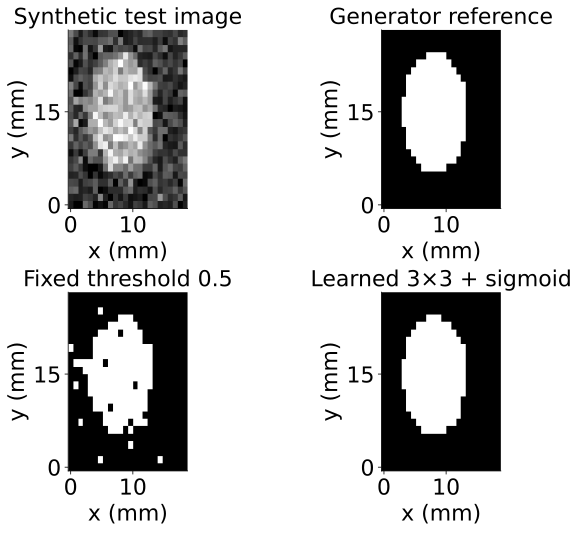

In [1]:
from demo import run
from IPython.display import SVG, display
report = run()
print('Selected training step:', report['training']['selected_step'])
print('Gradient discrepancy:', report['checks']['central_difference_gradient_max_abs_error'])
print(report['test_mean_per_image_metrics'])
display(SVG(filename='segmentation-comparison.svg'))

Interpret: inspect the learned kernel and compare its center and surrounding weights. The weights are shared at every pixel. Check one per-image result before discussing the averages.

[[1.77968667 2.02663615 1.82799649]
 [2.03545709 2.49814769 2.08254299]
 [1.7803918  2.1179453  1.79269329]]
{'case_id': 'test-00', 'baseline': {'dice': 0.9212121212121213, 'signed_area_error_percent': 0.0, 'mean_symmetric_boundary_distance_mm': 0.659331571772719, 'hausdorff_boundary_distance_mm': 6.788225099390857, 'foreground_components_4_connected': 9}, 'convolution': {'dice': 0.9939024390243902, 'signed_area_error_percent': -1.2121212121212122, 'mean_symmetric_boundary_distance_mm': 0.041025641025641026, 'hausdorff_boundary_distance_mm': 0.8, 'foreground_components_4_connected': 1}}


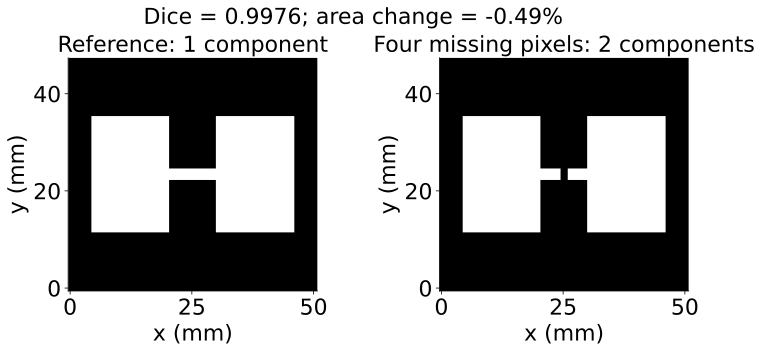

In [2]:
import numpy as np
print(np.array(report['weights_3x3']))
print(report['test_case_metrics'][0])
display(SVG(filename='connectivity-failure.svg'))

Modify the geometric stress test, not the frozen test-selection settings. Restore the bridge, then remove a different small block of foreground pixels. Predict overlap and connectivity first. Record the exact edit; this is a controlled counterexample, not a new training run.

In [3]:
from demo import bridge_example, metrics
reference, original_cut = bridge_example()
modified = reference.copy()
modified[10:12, 6:8] = False  # an outer corner, not the bridge
print('Bridge cut:', metrics(original_cut, reference))
print('Corner edit:', metrics(modified, reference))

Bridge cut: {'dice': 0.9975669099756691, 'signed_area_error_percent': -0.4854368932038835, 'mean_symmetric_boundary_distance_mm': 0.009302325581395349, 'hausdorff_boundary_distance_mm': 0.8, 'foreground_components_4_connected': 2}
Corner edit: {'dice': 0.9975669099756691, 'signed_area_error_percent': -0.4854368932038835, 'mean_symmetric_boundary_distance_mm': 0.016313069495444033, 'hausdorff_boundary_distance_mm': 1.6, 'foreground_components_4_connected': 1}
